# COMP7015 Group Project – Topic 1: Plant Disease Classification

We classify tomato leaf images from the [PlantVillage dataset](https://github.com/spMohanty/PlantVillage-Dataset) into **healthy, early blight, leaf mold and spider mites** (two-spotted spider mite damage). We compare a custom CNN with attention, a fine-tuned ResNet18 and a fine-tuned Vision Transformer. Then we ask how robust they are: to the photo background, to colour, lighting and image quality, and to photos taken outside the lab. Every class comes from its own photo series with its own background. 

## 1. Setup & Configuration

The settings live in four dictionaries in `plantdisease/config.py`: `PATHS_CONFIG` (where data and results live), `DATA_CONFIG` (the PlantVillage protocol), `PLANTDOC_CONFIG` (the PlantDoc field photos) and `TRAIN_CONFIG` (training seeds, background-swap probability).

In [1]:
import os

import matplotlib.pyplot as plt
import pandas as pd
import torch
import torchvision
from torchvision.utils import make_grid

from plantdisease.config import DATA_CONFIG, PATHS_CONFIG, SHORT_NAMES, out_path
from plantdisease.data.dataset import class_weights
from plantdisease.data.download import download_plantvillage
from plantdisease.data.images import build_cache
from plantdisease.data.loaders import CachedDataset, make_loader, train_tf
from plantdisease.data.records import data_fingerprint, load_records, make_split
from plantdisease.device import USE_AMP, device

In [2]:
DATA_CONFIG

{'classes': ['Tomato___healthy',
  'Tomato___Bacterial_spot',
  'Tomato___Early_blight',
  'Tomato___Late_blight'],
 'train_series': {'Tomato___healthy': 'rs_hl',
  'Tomato___Bacterial_spot': 'gcrec_bact.sp',
  'Tomato___Early_blight': 'rs_erly.b',
  'Tomato___Late_blight': 'rs_late.b'},
 'min_series_photos': 20,
 'img_size': 224,
 'split_seed': 62,
 'split_fractions': (0.7, 0.15),
 'num_workers': 2}

In [3]:
print("Device in use:", device, "| mixed precision:", USE_AMP)
print("torch", torch.__version__, "| torchvision", torchvision.__version__)

Device in use: cuda:0 | mixed precision: True
torch 2.15.0+cu132 | torchvision 0.29.2+cu132


## 2. Download the Data

We download the whole PlantVillage repository. We use the four tomato folders of `raw/color` (the RGB images used for training). We also use `raw/segmented`, the same photos with the background removed.

In [4]:
download_plantvillage()  # git clone of the whole repository, skipped if it exists
for kind in ("color", "segmented"):
    for class_name in DATA_CONFIG["classes"]:
        folder = f"raw/{kind}/{class_name}"
        n_images = len(os.listdir(os.path.join(PATHS_CONFIG["data_root"], folder)))
        print(f"{folder:60s} {n_images} images")

raw/color/Tomato___healthy                                   1591 images
raw/color/Tomato___Bacterial_spot                            2127 images
raw/color/Tomato___Early_blight                              1000 images
raw/color/Tomato___Late_blight                               1909 images
raw/segmented/Tomato___healthy                               1591 images
raw/segmented/Tomato___Bacterial_spot                        2127 images
raw/segmented/Tomato___Early_blight                          1000 images
raw/segmented/Tomato___Late_blight                           1909 images


## 3. Leaf Grouping & Label Verification

Every image must be assigned to a **physical leaf**, so that all photos of one leaf end up in the same split.

1. **Official metadata.** The image identifier from the file name is looked up in `leaf-map.json`, keeping only an entry of the image's own class. Most leaves are photographed four times.
2. **One training series per class.** A class can consist of several photo series (the series is the first part of the file name, for example `RS_HL` or `GH_HL`) with their own background, light and camera. We train on **one series per class that has official leaf ids** (`DATA_CONFIG[train_series]`): `RS_HL` (healthy), `RS_Erly.B` (early blight), `Crnl_L.Mold` (leaf mold) and `Com.G_SpM_FL` (spider mites). Early blight, leaf mold and spider mites have only this one series.
3. **Series test.** The healthy greenhouse series `GH_HL` has no official leaf ids. It is left out of training, validation and the clean test and is used in notebook 05 (Section 19.1) as photos of the same class from a different series.
4. **Exclusion.** Photos of a training series without any leaf information are excluded.

In [5]:
# leaf ids from leaf-map.json, training series vs. left-out series (plantdisease/data/: load_records)
leaf_map, all_df, df, other_df = load_records()

all_df.groupby(["class_name", "series"]).agg(
    photos=("path", "size"),
    official_ids=("source", lambda s: int((s == "leaf map").sum())),
    role=("training_series", lambda s: "training" if s.all() else "not trained on"),
).loc[DATA_CONFIG["classes"]]

photos  official_ids  \
class_name              series                                          
Tomato___healthy        2700323949_95aa2eaa01_o       1             0   
                        cg1                           1             0   
                        gh_hl                       590             0   
                        rs_hl                       999           999   
Tomato___Bacterial_spot gcrec_bact.sp              1756          1756   
                        uf.grc_bs_lab               371           371   
Tomato___Early_blight   rs_erly.b                  1000           999   
Tomato___Late_blight    gh_hl                         2             0   
                        ghlb                         66             0   
                        ghlb2                       744             0   
                        ghlb2es                      27             0   
                        ghlb_ps                     150             0   
                        rs_late.b                   920           920   

                                                           role  
class_name              series                                   
Tomato___healthy        2700323949_95aa2eaa01_o  not trained on  
                        cg1                      not trained on  
                        gh_hl                    not trained on  
                        rs_hl                          training  
Tomato___Bacterial_spot gcrec_bact.sp                  training  
                        uf.grc_bs_lab            not trained on  
Tomato___Early_blight   rs_erly.b                      training  
Tomato___Late_blight    gh_hl                    not trained on  
                        ghlb                     not trained on  
                        ghlb2                    not trained on  
                        ghlb2es                  not trained on  
                        ghlb_ps                  not trained on  
                        rs_late.b                      training

## 4. Image Cache

**Caching.** Decoding JPEGs and resizing them in every epoch is wasted work. Each image is decoded, converted to RGB and resized to 224×224 **once**, then stored as one `uint8` tensor in `cache/`. Training then only applies cheap tensor operations. The cache is rebuilt automatically if the image list or size changes.

In [6]:
# decoded + resized once, uint8 (N, 3, 224, 224)
images: torch.Tensor = build_cache(df["path"], "color")
labels: torch.Tensor = torch.tensor(df["class_index"].values)
print(f"Cached images: {tuple(images.shape)}, {images.numel() / 1e9:.2f} GB")

Cached images: (4674, 3, 224, 224), 0.70 GB


## 5. Leaf-Group Split & Leakage Audit

Within each class, the official leaf ids are shuffled with a fixed seed and split 70 / 15 / 15 into train / validation / test. All photos of one leaf follow its leaf id. The split seed is separate from the training seeds, so all models and seeds share **exactly the same split**. The audit asserts that no official leaf id appears in two splits.

In [7]:
# 70/15/15 split of the official leaf ids of every class; the audit is asserted inside make_split
train_idx, val_idx, test_idx = make_split(df)
print(
    f"Split seed: {DATA_CONFIG['split_seed']} | every official leaf id lies in exactly one split"
)
# fingerprint of the training photos, the series and the split seed: a saved run is only reused for the same data
data_id = data_fingerprint(df, train_idx)

df[["path", "class_name", "leaf_id", "split"]].to_csv(
    out_path("split.csv"), index=False
)
counts = pd.crosstab(df["class_name"], df["split"], margins=True).reindex(
    [*DATA_CONFIG["classes"], "All"]
)[["train", "val", "test", "All"]]
counts["leaf ids"] = [
    *df.groupby("class_name")["leaf_id"]
    .nunique()
    .reindex(DATA_CONFIG["classes"])
    .tolist(),
    df.leaf_id.nunique(),
]
counts.to_csv(out_path("class_counts.csv"))
counts

Split seed: 62 | every official leaf id lies in exactly one split


split,train,val,test,All,leaf ids
class_name,,,,,
Tomato___healthy,699,152,148,999,250
Tomato___Bacterial_spot,1228,264,264,1756,439
Tomato___Early_blight,700,151,148,999,250
Tomato___Late_blight,644,136,140,920,230
All,3271,703,700,4674,1169


## 6. Preprocessing, Augmentation & Class Weights

The cached images are already resized to 224×224 (the whole photo, no crop). Every split is converted to float in [0, 1] and normalised with the ImageNet mean/std. The same preprocessing is used for all models, including the ViT.

**Training-only augmentation** must not change the symptoms:
- horizontal/vertical flips and **rotations by multiples of 90°**, because a leaf has no fixed orientation. These rotations are lossless and add no black corners, which matters because the background could carry class information (Section 4).
- a mild brightness/contrast jitter (±10%) for lighting changes. There is no hue/saturation change, so lesion colours (yellow halos, brown spots, mould) are preserved.

**Class balance.** Spider mites have about 1.7× more training images than the other classes. Rather than throwing data away, the CNNs use a **class-weighted cross-entropy loss** with weight $w_c = N / (K \cdot n_c)$, so errors on smaller classes cost more. Section 9 tests whether this helps. The ViT follows Zhouyang's protocol without class weights (notebook 03).

The transforms, the cached dataset and the loaders are defined in `plantdisease/data/`.

Class weights: {'healthy': 1.1699999570846558, 'Bacterial_spot': 0.6660000085830688, 'Early_blight': 1.1679999828338623, 'Late_blight': 1.2699999809265137}


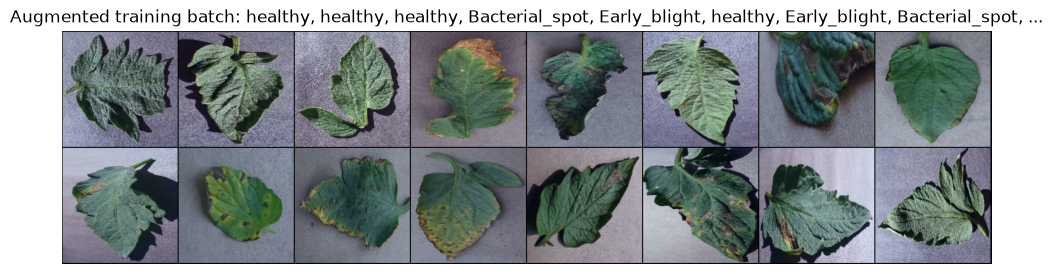

In [8]:
weights = class_weights(df, train_idx)  # w_c = N / (K * n_c)
print(
    "Class weights:",
    dict(zip(SHORT_NAMES, weights.numpy().round(3).tolist(), strict=True)),
)

# Visualise augmented training images
dataset = CachedDataset(images, labels, train_idx, train_tf)
x, y = next(iter(make_loader(dataset, 16, seed=0)))
plt.figure(figsize=(12, 3.5))
plt.imshow(make_grid(x, nrow=8, padding=2, normalize=True).permute(1, 2, 0))
plt.axis("off")
plt.title(
    "Augmented training batch: " + ", ".join(SHORT_NAMES[c] for c in y[:8]) + ", ..."
)
plt.show()

**Hand-over.** The following notebooks rebuild exactly this data protocol with `plantdisease.data.prepare()`, which runs the same steps (records, cache, split) from the image cache in a few seconds. The split is saved to `OUT_DIR/split.csv`.